In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

# Load the development data
dev_data = pd.read_csv('Dev_data_to_be_shared.csv')

# Check basic info and null values
print("Initial Data Overview:")
print(dev_data.info())
print("\nMissing values:")
print(dev_data.isnull().sum())

Initial Data Overview:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96806 entries, 0 to 96805
Columns: 1216 entries, account_number to onus_attribute_48
dtypes: float64(1189), int64(27)
memory usage: 898.1 MB
None

Missing values:
account_number                 0
bad_flag                       0
onus_attribute_1           25231
transaction_attribute_1    25231
transaction_attribute_2    25231
                           ...  
onus_attribute_44          85196
onus_attribute_45          85196
onus_attribute_46          85196
onus_attribute_47          85196
onus_attribute_48          85196
Length: 1216, dtype: int64


In [2]:
dev_data.shape

(96806, 1216)

In [3]:
# Calculate the percentage of NaNs in each column
nan_percentage = dev_data.isnull().mean() * 100

# Drop columns with more than 50% NaNs
columns_to_drop = nan_percentage[nan_percentage > 20].index
dev_data_cleaned = dev_data.drop(columns=columns_to_drop)

# Check the new shape of the data
print(dev_data_cleaned.shape)


(96806, 521)


In [4]:

dev_data_cleaned.fillna(dev_data.mean(),inplace=True)
# dev_data = dev_data.round().astype(int)
# Separate features and target variable
y = dev_data_cleaned['bad_flag']
y.columns=['bad_flag']
X= dev_data_cleaned.drop(['bad_flag'], axis=1)



In [5]:
print(X.columns)

Index(['account_number', 'bureau_1', 'bureau_2', 'bureau_3', 'bureau_4',
       'bureau_5', 'bureau_6', 'bureau_7', 'bureau_8', 'bureau_9',
       ...
       'bureau_enquiry_41', 'bureau_enquiry_42', 'bureau_enquiry_43',
       'bureau_enquiry_44', 'bureau_enquiry_45', 'bureau_enquiry_46',
       'bureau_enquiry_47', 'bureau_enquiry_48', 'bureau_enquiry_49',
       'bureau_enquiry_50'],
      dtype='object', length=520)


In [6]:
print(y.columns)

['bad_flag']


In [7]:
dev_data_cleaned.isna().sum()

account_number       0
bad_flag             0
bureau_1             0
bureau_2             0
bureau_3             0
                    ..
bureau_enquiry_46    0
bureau_enquiry_47    0
bureau_enquiry_48    0
bureau_enquiry_49    0
bureau_enquiry_50    0
Length: 521, dtype: int64

In [8]:
X.isna().sum()

account_number       0
bureau_1             0
bureau_2             0
bureau_3             0
bureau_4             0
                    ..
bureau_enquiry_46    0
bureau_enquiry_47    0
bureau_enquiry_48    0
bureau_enquiry_49    0
bureau_enquiry_50    0
Length: 520, dtype: int64

In [9]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96806 entries, 0 to 96805
Columns: 520 entries, account_number to bureau_enquiry_50
dtypes: float64(494), int64(26)
memory usage: 384.1 MB


In [10]:
# Step 2: Standardize the features
# new_unnormalized_variance -= np.where(new_sample_count > 0, correction**2 / new_sample_count, 0)
from sklearn.decomposition import PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 3: Apply PCA
# Retain 95% of the variance
pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X_scaled)

# # Step 4: Check the number of components
print(f"Original number of features: {X_scaled.shape[1]}")
print(f"Reduced number of features after PCA: {X_pca.shape[1]}")

# # Step 5: Convert back to DataFrame
X_pca_df = pd.DataFrame(X_pca)

Original number of features: 520
Reduced number of features after PCA: 165


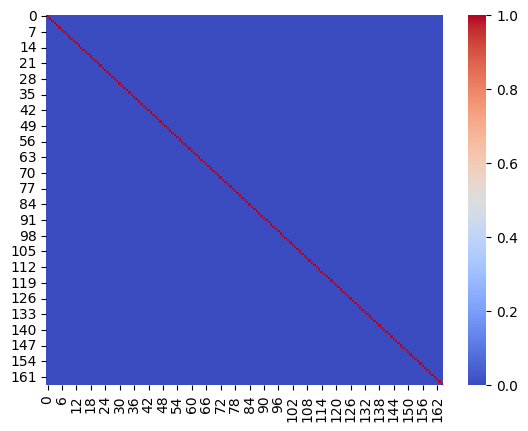

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt
corr=X_pca_df.corr()
sns.heatmap(corr,annot=False,cmap='coolwarm')
plt.show()

In [12]:
X_pca_df 

,0,1,2,3,4,5,6,7,8,9,...,155,156,157,158,159,160,161,162,163,164
0,24.574505,-15.369900,-19.867934,0.404049,-2.203734,-4.848510,-8.092291,-11.422676,-2.626513,0.220930,...,-0.339635,-0.259031,-0.419823,-0.568194,0.558238,0.382149,-0.500884,-0.354208,0.188565,-0.196413
1,2.231786,7.282335,4.370950,7.424308,11.575598,-3.785853,5.484648,-0.933697,-3.584131,-9.687874,...,0.419949,-0.560538,-0.450573,-0.005456,1.128609,-0.342284,-0.560541,0.995547,0.707456,-0.391483
2,-4.427161,0.170432,0.214828,-3.888406,0.344228,1.154318,-0.388959,-0.215543,0.985048,1.137033,...,-0.035242,-0.015607,0.016501,0.013043,0.011985,0.047628,0.029001,-0.270400,-0.181676,-0.355337
3,15.500270,-1.392355,-9.482123,-5.437004,1.707040,-0.471239,-2.053898,-4.130258,0.630052,2.965570,...,-0.795494,0.148304,-0.981978,-0.146370,-0.055477,0.547154,0.711968,0.317581,0.430394,-0.508062
4,-0.880040,-5.184113,-0.737892,7.876096,-2.641673,-2.394594,-4.405807,3.763156,-2.381018,-1.031058,...,0.582277,0.579946,1.184102,-0.057468,-0.237582,-0.017793,-0.477230,-0.659851,-0.604829,0.138502
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96801,1.655379,3.154751,-1.293264,1.054490,0.802407,-1.615775,2.010074,-2.335556,-0.989082,-6.169851,...,-0.261781,-0.315389,-0.713808,-0.038256,0.022845,0.155145,-0.192195,0.716643,1.156131,-0.045581
96802,9.298466,-5.760400,-5.984005,-8.444391,2.223012,0.491535,1.052711,-4.898460,1.800815,0.335245,...,0.776700,-0.212594,1.071889,-0.167433,0.200740,-0.217951,-0.291021,-0.199477,0.358826,-0.738652
96803,1.670485,11.168283,-4.770666,-0.970618,-3.278125,0.592430,-5.160524,-2.385908,1.695102,0.220673,...,-0.067001,-0.327310,-0.187474,0.046464,0.038372,0.154887,-0.374928,0.113876,0.355358,0.353831
96804,-1.155688,3.541269,0.330911,3.343574,-0.890076,-0.082117,1.823559,0.228503,-2.140738,0.712425,...,-0.074325,-0.701383,-0.389073,-0.200952,0.525446,0.291314,0.403717,-0.239763,0.018940,-0.102981


In [ ]:

# Split the data into training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_pca_df , y, test_size=0.3, random_state=42)

# Train a Logistic Regression model
log_reg = LogisticRegression()
log_reg.fit(X_train, y_train)

# Train a Random Forest model
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_clf.fit(X_train, y_train)

# Evaluate the models on the test set
y_pred_log = log_reg.predict_proba(X_test)[:, 1]
y_pred_rf = rf_clf.predict_proba(X_test)[:, 1]

# Calculate AUC scores
log_auc = roc_auc_score(y_test, y_pred_log)
rf_auc = roc_auc_score(y_test, y_pred_rf)
print(f"Logistic Regression AUC: {log_auc:.4f}")
print(f"Random Forest AUC: {rf_auc:.4f}")
